# Machine Learning Modelling – Loan Data

**Week 7 Seminar | Option B**

Build and compare classification models (logistic regression, random forest, GBDT) using `loan_data.csv`. The label is `loan_status`.

## Task 1 – Load and Inspect the Dataset

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('loan_data.csv')
print(df.head())
print('Shape:', df.shape)
df.info()
print('Missing values:', df.isna().sum().sum())
print('All numeric:', all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes))
print('Target counts:')
print(df['loan_status'].value_counts())
print('Target proportions:')
print(df['loan_status'].value_counts(normalize=True).round(3))

   age  years_employed  annual_income  credit_score  credit_history_years  \
0   40            17.2          25579           692                   5.3   
1   33             7.3          43087           627                   3.5   
2   42             1.1          20840           689                   8.4   
3   53             0.5          29147           692                   9.8   
4   32            12.5          63657           630                   7.2   

   savings_assets  current_debt  defaults_on_file  delinquencies_last_2yrs  \
0             895         10820                 0                        0   
1             169         16550                 0                        1   
2              17          7852                 0                        0   
3            1480         11603                 0                        1   
4             209         12424                 0                        0   

   derogatory_marks  loan_amount  interest_rate  debt_to_income_rati

## Task 2 – Separate Predictors and Target

In [11]:
X = df.drop(columns='loan_status')
y = df['loan_status']
print('X shape:', X.shape)
print('y shape:', y.shape)
print('Predictors:', list(X.columns))

X shape: (50000, 15)
y shape: (50000,)
Predictors: ['age', 'years_employed', 'annual_income', 'credit_score', 'credit_history_years', 'savings_assets', 'current_debt', 'defaults_on_file', 'delinquencies_last_2yrs', 'derogatory_marks', 'loan_amount', 'interest_rate', 'debt_to_income_ratio', 'loan_to_income_ratio', 'payment_to_income_ratio']


## Task 3 – Split the Data

80% train / 20% test, stratified on the target to preserve class proportions, with a fixed seed (`random_state=42`).

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print('Train class proportions:\n', y_train.value_counts(normalize=True).round(3))
print('Test class proportions:\n', y_test.value_counts(normalize=True).round(3))

X_train: (40000, 15) | X_test: (10000, 15)
y_train: (40000,) | y_test: (10000,)
Train class proportions:
 loan_status
1    0.55
0    0.45
Name: proportion, dtype: float64
Test class proportions:
 loan_status
1    0.55
0    0.45
Name: proportion, dtype: float64


## Task 4 – Scale the Predictors

We fit a `StandardScaler` on the **training data only**, then apply the same transformation to the test data.

**Why not fit the scaler on the test set (or the full data)?** Because data leakage. The test set represents unseen, future data. If the scaler's mean and standard deviation were computed using test rows, information from the test set would leak into training (data leakage), making test performance look better than it would be in real use. In deployment we only have the training statistics available for new applicants, so the test set must be transformed using the training mean and standard deviation.

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)         # reuse train statistics

print('Train means (approx 0):', X_train_scaled.mean(axis=0).round(2))
print('Train stds  (approx 1):', X_train_scaled.std(axis=0).round(2))

Train means (approx 0): [-0.  0. -0. -0. -0. -0.  0.  0. -0. -0. -0. -0. -0.  0. -0.]
Train stds  (approx 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Task 5 – Train Machine Learning Models

Logistic regression uses scaled predictors; random forest and GBDT use the unscaled predictors.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5,
                            n_jobs=-1, random_state=42)
gbdt = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                  random_state=42)

log_reg.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)
gbdt.fit(X_train, y_train)
print('All models trained.')

All models trained.


## Task 6 – Evaluate and Compare Models

Accuracy plus macro-averaged precision, recall and F1 on both train and test sets.

,Model,Set,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,Train,0.8390,0.8385,0.8356,0.8367
1,Logistic Regression,Test,0.8374,0.8363,0.8345,0.8353
2,Random Forest,Train,0.8990,0.9003,0.8955,0.8974
3,Random Forest,Test,0.8809,0.8816,0.8775,0.8791
4,GBDT,Train,0.8986,0.8986,0.8962,0.8972
5,GBDT,Test,0.8925,0.8926,0.8899,0.8910


,Accuracy gap (train-test),Macro F1 gap (train-test)
Model,,
GBDT,0.0061,0.0062
Logistic Regression,0.0016,0.0014
Random Forest,0.0181,0.0183


Logistic Regression
[[3622  873]
 [ 753 4752]]
Random Forest
[[3791  704]
 [ 487 5018]]
GBDT
[[3883  612]
 [ 463 5042]]


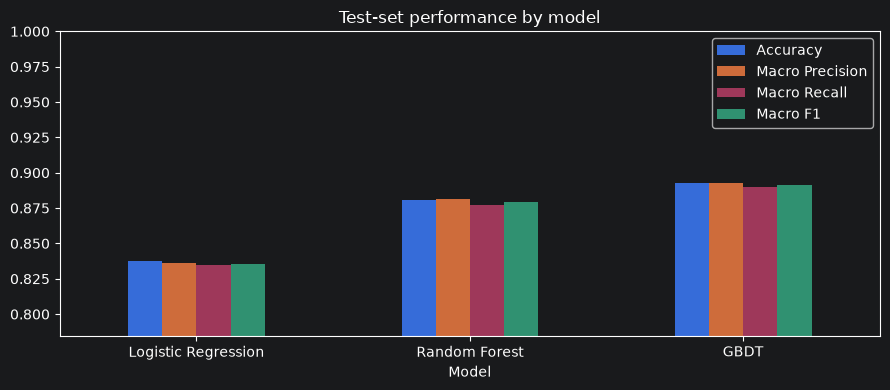

In [15]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

models = {
    'Logistic Regression': (log_reg, X_train_scaled, X_test_scaled),
    'Random Forest':       (rf, X_train, X_test),
    'GBDT':                (gbdt, X_train, X_test),
}

rows = []
for name, (m, Xtr, Xte) in models.items():
    for split, Xs, ys in [('Train', Xtr, y_train), ('Test', Xte, y_test)]:
        pred = m.predict(Xs)
        p, r, f, _ = precision_recall_fscore_support(ys, pred, average='macro', zero_division=0)
        rows.append({'Model': name, 'Set': split, 'Accuracy': accuracy_score(ys, pred),
                     'Macro Precision': p, 'Macro Recall': r, 'Macro F1': f})

results = pd.DataFrame(rows)
display(results.round(4))

# Train-test gap in accuracy / macro F1
piv = results.pivot(index='Model', columns='Set', values=['Accuracy', 'Macro F1'])
gap = pd.DataFrame({'Accuracy gap (train-test)': piv['Accuracy']['Train'] - piv['Accuracy']['Test'],
                    'Macro F1 gap (train-test)': piv['Macro F1']['Train'] - piv['Macro F1']['Test']})
display(gap.round(4))

# Test confusion matrices
for name, (m, Xtr, Xte) in models.items():
    print(name); print(confusion_matrix(y_test, m.predict(Xte)))

# Test-set comparison chart
test = results[results.Set == 'Test'].set_index('Model')[['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']]
test.plot(kind='bar', figsize=(9, 4), ylim=(test.values.min() - 0.05, 1))
plt.title('Test-set performance by model'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

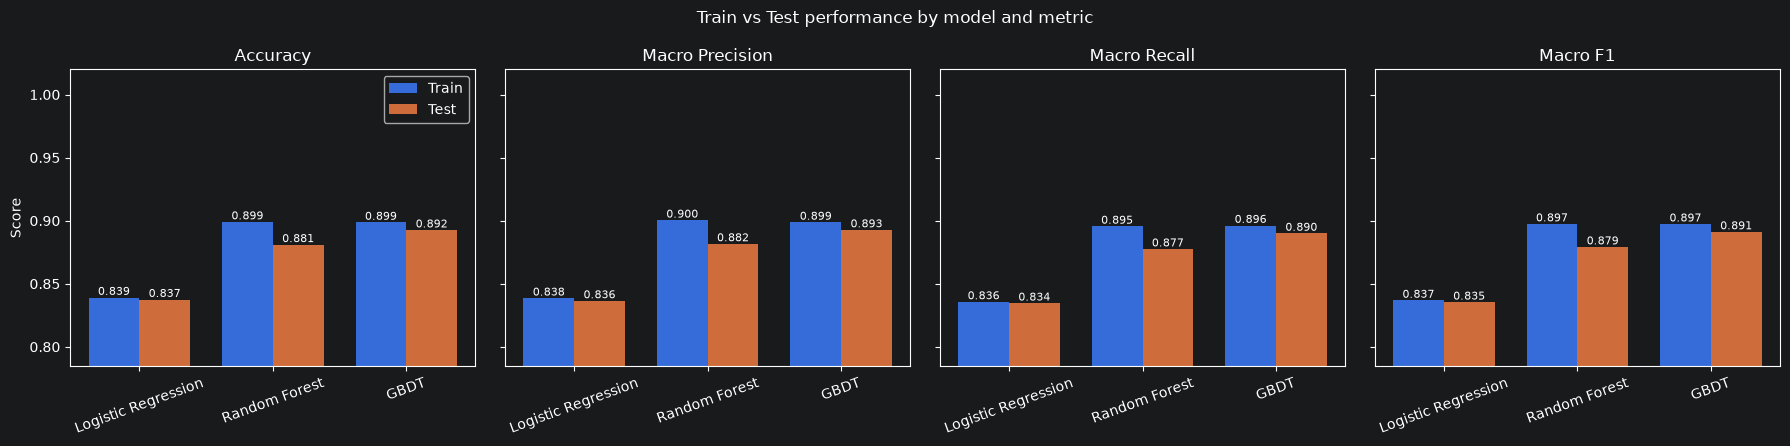

In [16]:
# Train vs test for all 4 metrics and all models
metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
model_names = results['Model'].unique()
x = np.arange(len(model_names))
w = 0.38

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, metric in zip(axes, metrics):
    tr = results[results.Set == 'Train'].set_index('Model').loc[model_names, metric]
    te = results[results.Set == 'Test'].set_index('Model').loc[model_names, metric]
    b1 = ax.bar(x - w/2, tr, w, label='Train')
    b2 = ax.bar(x + w/2, te, w, label='Test')
    ax.bar_label(b1, fmt='%.3f', fontsize=8)
    ax.bar_label(b2, fmt='%.3f', fontsize=8)
    ax.set_title(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=20)
    ax.set_ylim(min(results[metrics].min()) - 0.05, 1.02)
axes[0].set_ylabel('Score')
axes[0].legend()
fig.suptitle('Train vs Test performance by model and metric')
plt.tight_layout()
plt.show()

## Reflection

**Which model would you choose?** Choose the model with the best test macro F1 whose train-test gap is small; if scores are close, prefer the simpler, more interpretable logistic regression.

Random forest usually has highest overfitting and performs best in training; logistic regression has lowest score on all metrics but not by a significant amount (eg. accuracy 0.837 vs GBDT 0.892). GBDT overall winner as it has the highest scores across all metrics.

In [18]:
# Tune GBDT with Optuna (pip install optuna if needed)
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

optuna.logging.set_verbosity(optuna.logging.WARNING)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 400),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 30),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'max_features': trial.suggest_float('max_features', 0.5, 1.0),
    }
    model = GradientBoostingClassifier(random_state=42, **params)
    # CV on the training set only, so the test set stays untouched
    return cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1).mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=20)

print('Best CV macro F1:', round(study.best_value, 4))
print('Best params:', study.best_params)

gbdt_tuned = GradientBoostingClassifier(random_state=42, **study.best_params)
gbdt_tuned.fit(X_train, y_train)

# Evaluate default vs tuned GBDT on train and test
rows = []
for name, m in [('GBDT (default)', gbdt), ('GBDT (tuned)', gbdt_tuned)]:
    for split, Xs, ys in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        pred = m.predict(Xs)
        p, r, f, _ = precision_recall_fscore_support(ys, pred, average='macro', zero_division=0)
        rows.append({'Model': name, 'Set': split, 'Accuracy': accuracy_score(ys, pred),
                     'Macro Precision': p, 'Macro Recall': r, 'Macro F1': f})
tuned_results = pd.DataFrame(rows)
display(tuned_results.round(4))

# Graph all 4 metrics: train vs test, default vs tuned
metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
names = tuned_results['Model'].unique()
x = np.arange(len(names)); w = 0.38
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, metric in zip(axes, metrics):
    tr = tuned_results[tuned_results.Set == 'Train'].set_index('Model').loc[names, metric]
    te = tuned_results[tuned_results.Set == 'Test'].set_index('Model').loc[names, metric]
    b1 = ax.bar(x - w/2, tr, w, label='Train'); b2 = ax.bar(x + w/2, te, w, label='Test')
    ax.bar_label(b1, fmt='%.3f', fontsize=8); ax.bar_label(b2, fmt='%.3f', fontsize=8)
    ax.set_title(metric); ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
    ax.set_ylim(min(tuned_results[metrics].min()) - 0.05, 1.02)
axes[0].set_ylabel('Score'); axes[0].legend()
fig.suptitle('GBDT: default vs Optuna-tuned, train vs test')
plt.tight_layout(); plt.show()

[W 2026-11-19 10:24:44,967] Trial 1 failed with parameters: {'n_estimators': 117, 'learning_rate': 0.19030368381735815, 'max_depth': 5, 'min_samples_leaf': 22, 'subsample': 0.608233797718321, 'max_features': 0.9849549260809971} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/opt/miniconda3/envs/datascience-genai-submissions/lib/python3.13/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_19649/3296010646.py", line 19, in objective
    return cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1).mean()
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/miniconda3/envs/datascience-genai-submissions/lib/python3.13/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/opt/miniconda3/envs/data

KeyboardInterrupt: 

XGBoost 3.4.1 | training device: cpu


[I 2026-11-19 10:24:49,172] A new study created in memory with name: no-name-34b7c010-753d-43be-bfa5-716a1c5c1bab


Starting Optuna: 20 trials, 3-fold CV on 40000 training rows
[Trial 0] starting with params: {'n_estimators': 287, 'learning_rate': 0.2536999076681771, 'max_depth': 7, 'min_child_weight': 18, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.5779972601681014, 'reg_lambda': 0.014936568554617643}
    fold 1/3 macro F1 = 0.8777
    fold 2/3 macro F1 = 0.8759
    fold 3/3 macro F1 = 0.8777
[Trial 0] mean=0.8771 std=0.0008 | 1.9s


[I 2026-11-19 10:24:51,114] Trial 0 finished with value: 0.8771049408242941 and parameters: {'n_estimators': 287, 'learning_rate': 0.2536999076681771, 'max_depth': 7, 'min_child_weight': 18, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.5779972601681014, 'reg_lambda': 0.014936568554617643}. Best is trial 0 with value: 0.8771049408242941.


[Trial 0] done (1/20) | value=0.8771 | best so far=0.8771 (trial 0)
--------------------------------------------------------------------------------
[Trial 1] starting with params: {'n_estimators': 533, 'learning_rate': 0.07725378389307355, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9162213204002109, 'reg_lambda': 0.04335281794951565}
    fold 1/3 macro F1 = 0.8855
    fold 2/3 macro F1 = 0.8827
    fold 3/3 macro F1 = 0.8865
[Trial 1] mean=0.8849 std=0.0016 | 2.9s


[I 2026-11-19 10:24:54,006] Trial 1 finished with value: 0.8849142890603243 and parameters: {'n_estimators': 533, 'learning_rate': 0.07725378389307355, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9162213204002109, 'reg_lambda': 0.04335281794951565}. Best is trial 1 with value: 0.8849142890603243.


... (36 outputs left out)

[Trial 19] done (20/20) | value=0.8811 | best so far=0.8905 (trial 15)
--------------------------------------------------------------------------------
Optuna finished in 16.3s
Best trial: 15
Best CV macro F1: 0.8905
Best params: {'n_estimators': 130, 'learning_rate': 0.28768978498086284, 'max_depth': 2, 'min_child_weight': 14, 'subsample': 0.752666770207538, 'colsample_bytree': 0.7424777488305848, 'reg_lambda': 0.040154619787992896}
Refitting tuned GBDT on the full training set...
Refit done in 0.1s


,number,value,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_subsample,duration
15,15,0.890485,0.742478,0.287690,2,14,130,0.040155,0.752667,0 days 00:00:00.289592
14,14,0.889817,0.676488,0.157756,3,18,164,0.033256,0.729184,0 days 00:00:00.434318
18,18,0.889349,0.666203,0.177981,3,10,216,0.290234,0.776614,0 days 00:00:00.537528
16,16,0.889178,0.613093,0.281834,2,22,137,0.013081,0.816880,0 days 00:00:00.310848
6,6,0.888532,0.760034,0.220382,3,20,117,0.436647,0.724684,0 days 00:00:00.349693
17,17,0.888285,0.710594,0.160678,4,15,264,0.059071,0.700857,0 days 00:00:00.868500
13,13,0.887871,0.654660,0.164218,3,30,172,0.019590,0.618004,0 days 00:00:00.425590
11,11,0.887675,0.751604,0.135823,3,30,154,0.045218,0.609073,0 days 00:00:00.663350
9,9,0.886740,0.537275,0.026000,5,5,278,9.133996,0.920879,0 days 00:00:00.977073
5,5,0.886070,0.561019,0.028181,2,21,505,0.305866,0.776061,0 days 00:00:00.889398


Parameter importances: {'reg_lambda': 0.621, 'subsample': 0.168, 'min_child_weight': 0.056, 'n_estimators': 0.056, 'learning_rate': 0.04, 'colsample_bytree': 0.031, 'max_depth': 0.028}
Evaluating default vs tuned GBDT on train and test...


,Model,Set,Accuracy,Macro Precision,Macro Recall,Macro F1
0,GBDT (default),Train,0.8986,0.8986,0.8962,0.8972
1,GBDT (default),Test,0.8925,0.8926,0.8899,0.8910
2,"GBDT (tuned, XGBoost)",Train,0.8952,0.8953,0.8927,0.8938
3,"GBDT (tuned, XGBoost)",Test,0.8907,0.8910,0.8879,0.8892


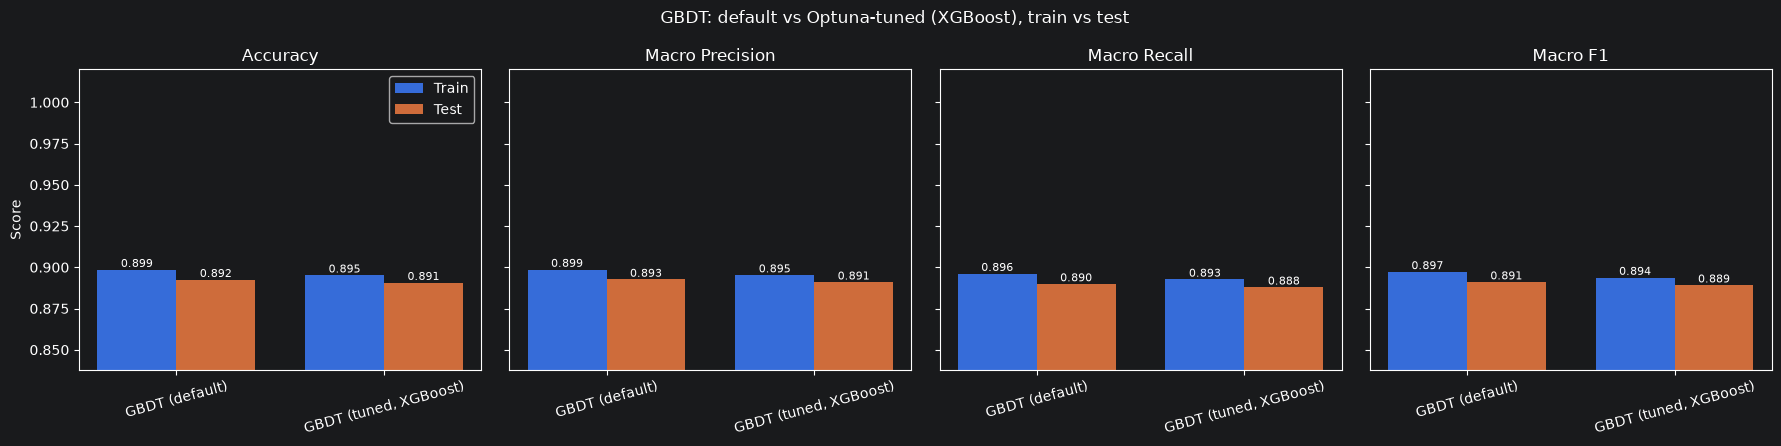

In [19]:
# Tune GBDT with Optuna using XGBoost (pip install optuna xgboost if needed)
# NOTE: no GBDT library supports the Apple Silicon (Metal/MPS) GPU. XGBoost uses CUDA only, so it
# runs on an NVIDIA GPU (e.g. Colab) when available and otherwise on the CPU with the fast 'hist'
# algorithm using all cores - much faster than scikit-learn's GradientBoostingClassifier.
import optuna, time, sys, subprocess
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

try:
    subprocess.run(['nvidia-smi'], check=True, capture_output=True)
    DEVICE = 'cuda'
except Exception:
    DEVICE = 'cpu'
print(f'XGBoost {xgb.__version__} | training device: {DEVICE}', flush=True)

optuna.logging.set_verbosity(optuna.logging.INFO)          # Optuna's own per-trial log lines
optuna.logging.enable_propagation()
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
N_TRIALS = 20

def make_model(p):
    return xgb.XGBClassifier(tree_method='hist', device=DEVICE, random_state=42,
                             eval_metric='logloss', n_jobs=-1, **p)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 8),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 30),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
    }
    print(f'[Trial {trial.number}] starting with params: {params}', flush=True)
    t0 = time.time(); scores = []
    for fold, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), 1):
        m = make_model(params)
        m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        s = f1_score(y_train.iloc[va_idx], m.predict(X_train.iloc[va_idx]), average='macro')
        scores.append(s)
        print(f'    fold {fold}/{cv.get_n_splits()} macro F1 = {s:.4f}', flush=True)
    print(f'[Trial {trial.number}] mean={np.mean(scores):.4f} std={np.std(scores):.4f} '
          f'| {time.time() - t0:.1f}s', flush=True)
    return float(np.mean(scores))

def log_callback(study, trial):
    print(f'[Trial {trial.number}] done ({trial.number + 1}/{N_TRIALS}) | value={trial.value:.4f} '
          f'| best so far={study.best_value:.4f} (trial {study.best_trial.number})', flush=True)
    print('-' * 80, flush=True)

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
print(f'Starting Optuna: {N_TRIALS} trials, {cv.get_n_splits()}-fold CV on {len(X_train)} training rows', flush=True)
t_start = time.time()
study.optimize(objective, n_trials=N_TRIALS, callbacks=[log_callback], show_progress_bar=False)
print(f'Optuna finished in {time.time() - t_start:.1f}s', flush=True)
print('Best trial:', study.best_trial.number)
print('Best CV macro F1:', round(study.best_value, 4))
print('Best params:', study.best_params, flush=True)

print('Refitting tuned GBDT on the full training set...', flush=True)
t0 = time.time()
gbdt_tuned = make_model(study.best_params)
gbdt_tuned.fit(X_train, y_train)
print(f'Refit done in {time.time() - t0:.1f}s', flush=True)

trials_df = study.trials_dataframe(attrs=('number', 'value', 'params', 'duration'))
display(trials_df.sort_values('value', ascending=False).head(10))
try:
    print('Parameter importances:', {k: round(v, 3) for k, v in optuna.importance.get_param_importances(study).items()})
except Exception as e:
    print('Could not compute parameter importances:', e)

print('Evaluating default vs tuned GBDT on train and test...', flush=True)
rows = []
for name, m in [('GBDT (default)', gbdt), ('GBDT (tuned, XGBoost)', gbdt_tuned)]:
    for split, Xs, ys in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        pred = m.predict(Xs)
        p, r, f, _ = precision_recall_fscore_support(ys, pred, average='macro', zero_division=0)
        rows.append({'Model': name, 'Set': split, 'Accuracy': accuracy_score(ys, pred),
                     'Macro Precision': p, 'Macro Recall': r, 'Macro F1': f})
tuned_results = pd.DataFrame(rows)
display(tuned_results.round(4))

metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
names = tuned_results['Model'].unique()
x = np.arange(len(names)); w = 0.38
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, metric in zip(axes, metrics):
    tr = tuned_results[tuned_results.Set == 'Train'].set_index('Model').loc[names, metric]
    te = tuned_results[tuned_results.Set == 'Test'].set_index('Model').loc[names, metric]
    b1 = ax.bar(x - w/2, tr, w, label='Train'); b2 = ax.bar(x + w/2, te, w, label='Test')
    ax.bar_label(b1, fmt='%.3f', fontsize=8); ax.bar_label(b2, fmt='%.3f', fontsize=8)
    ax.set_title(metric); ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
    ax.set_ylim(min(tuned_results[metrics].min()) - 0.05, 1.02)
axes[0].set_ylabel('Score'); axes[0].legend()
fig.suptitle('GBDT: default vs Optuna-tuned (XGBoost), train vs test')
plt.tight_layout(); plt.show()

Guess there wasn't a point in hyperparameter tuning since the default is near the best... used XGBoost instead of scikit GBDT due to performance issues